# NLP Assignment 1: Training Word2Vec on Child Speech

In this assignment, you will:

1. **Implement** and **Train** a Word2Vec (CBOW) model on a child speech dataset (50%).  
2. **Explore** word similarity using the learned embeddings (code: 20%; discussion: 15%).  
3. **Visualise** embeddings in 2D using SVD (15%).

**We will randomly run 15 submissions. If any bug occurs during execution OR the results fall outside a reasonable reproducible range compared to the logged results, the submission will receive 0 mark for this assignment.**

## 0. Load and clean the text data

In this step, we load the text file `1000_cs.txt` and pre-process each line by:
- Removing punctuation and special characters;
- Removing line breaks;
- Converting all text to lowercase;

The cleaned text is stored in `clean_sentences`, which will be then used to build the vocabulary and data for training the CBOW model.


In [11]:
import re
from collections import Counter

def preprocess(sentence):
    sentence = re.sub('[^A-Za-z0-9]+', ' ', sentence)
    sentence = re.sub('\n', '', sentence)
    sentence = sentence.lower()
    return sentence

sentences = open("1000_cs.txt", "r").readlines()
clean_sentences = [preprocess(sentence) for sentence in sentences]

# clean_sentences

## 1. Filter out low-frequency tokens

Here, we replace words that appear less than a minimum frequency (default=2) with the special token `<unk>`.  

This helps:
- Reduce vocabulary size
- Deal with unseen words
- Make the training process more stable

The filtered sentences are stored in `filtered_sentences`.

In [12]:
from collections import Counter

def filter_low_freq_tokens(sentences, min_freq=2, unk_token="<unk>"):
    filtered_sentences = []
    all_tokens = " ".join(sentences).split()
    word_counts = Counter(all_tokens)
    for s in sentences:
        toks = s.split()
        toks = [w if word_counts[w] >= min_freq else unk_token for w in toks]
        filtered_sentences.append(" ".join(toks))
    return filtered_sentences

filtered_sentences = filter_low_freq_tokens(clean_sentences, min_freq=2, unk_token="<unk>")

## 2. Build the CBOW training data

We now build the vocabulary and create training samples for the CBOW model.
- `vocab`: the list of unique words in the corpus  
- `word_to_ix` / `ix_to_word`: mappings between words and their indices  
- For each word in a sentence, we take a fixed-size context window (default=2)
  and use the surrounding words as input and the center word as the target.

Each training sample has the form: `(context_words, target_word)`.
The resulting dataset is stored in `data`.

In [3]:
def build_cbow_data(sentences, window_size=2):
    words = " ".join(sentences).split()
    vocab = set(words)

    word_to_ix = {word: i for i, word in enumerate(vocab)}
    ix_to_word = {i: word for i, word in enumerate(vocab)}

    data = []
    for s in sentences:
        ws = s.split()
        for i in range(window_size, len(ws) - window_size):
            context = [ws[i - j - 1] for j in reversed(range(window_size))] + \
                      [ws[i + j + 1] for j in range(window_size)]
            target = ws[i]
            data.append((context, target))

    return vocab, word_to_ix, ix_to_word, data

vocab, word_to_ix, ix_to_word, data = build_cbow_data(filtered_sentences, window_size=2)

data 

[(['i', 'knew', 'knew', 'there'], 'i'),
 (['knew', 'i', 'there', 'was'], 'knew'),
 (['i', 'knew', 'was', 'no'], 'there'),
 (['knew', 'there', 'no', 'letters'], 'was'),
 (['there', 'was', 'letters', 'didn'], 'no'),
 (['was', 'no', 'didn', 't'], 'letters'),
 (['no', 'letters', 't', 'you'], 'didn'),
 (['i', '<unk>', 'the', 'first'], 'em'),
 (['<unk>', 'em', 'first', 'time'], 'the'),
 (['em', 'the', 'time', 'and'], 'first'),
 (['the', 'first', 'and', 'it'], 'time'),
 (['first', 'time', 'it', 'was'], 'and'),
 (['time', 'and', 'was', '<unk>'], 'it'),
 (['de', 'man', 'it', 'in'], 'made'),
 (['man', 'made', 'in', 'dere'], 'it'),
 (['made', 'it', 'dere', 'and'], 'in'),
 (['it', 'in', 'and', 'den'], 'dere'),
 (['in', 'dere', 'den', 'he'], 'and'),
 (['that', 'that', 's', 'not'], 'horsie'),
 (['that', 'horsie', 'not', 'very'], 's'),
 (['horsie', 's', 'very', 'well'], 'not'),
 (['s', 'not', 'well', 'lady'], 'very'),
 (['to', 'make', 'campfire', 'we'], 'a'),
 (['make', 'a', 'we', 'made'], 'campfire'

## 3. Implement the CBOW model

To make the training process cleaner and more reusable, we wrap the core functions (`forward`, `backward`, `update`) into a `CBOW` class.

This helps:
- Keep model logic and training logic separate
- Make the code easier to read and maintain
- Allow easy extension (e.g., negative sampling or Skip-gram)

Please complete the functions in the below code based on the pseudo-code in the course slide.

In [4]:
import numpy as np

class CBOW:
    def __init__(self, vocab_size, embed_dim=100, lr=0.01):
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.lr = lr
        self.W_in = np.random.uniform(-0.01, 0.01, (vocab_size, embed_dim)).astype(np.float32)
        self.W_out = np.random.uniform(-0.01, 0.01, (embed_dim, vocab_size)).astype(np.float32)

    def log_softmax(self, x):
        x = x - np.max(x, axis=-1, keepdims=True)
        return x - np.log(np.exp(x).sum(axis=-1, keepdims=True))

    def forward(self, context_idxs):
        # forward is supplied with a numpy array of the index of each context word, according to our earlier vocab finding
        h = self.W_in[context_idxs].mean(axis=0, keepdims=True)

        # Get the similarity of the context vector with the surrounding vectors. 
        logits = h @ self.W_out
        log_probs = self.log_softmax(logits)

        return h, logits, log_probs

    def nll_loss(self, log_probs, target_idxs):
        return -log_probs[np.arange(len(target_idxs)), target_idxs].mean()

    def backward(self, preds, target_idxs, context_len):
        # backwards is supplied with the output of forwards, the actual solution, and the length of the context. 
        h, _, log_probs = preds

        dLogits = np.exp(log_probs)
        dLogits[0, target_idxs] -= 1.0  

        dW_out = h.T @ dLogits
        dh_each = dLogits @ self.W_out.T
        dh_each /= context_len

        return dW_out, dh_each

    def update(self, context_idxs, dW_out, dh_each):
        self.W_out -= self.lr * dW_out
        for i in context_idxs:
            self.W_in[i] -= self.lr * dh_each[0]

    def train_one_epoch(self, data):
        losses = []
        for context, target in data:
            context_idxs = np.array([word_to_ix[w] for w in context], dtype=np.int64)
            target_idxs = np.array([word_to_ix[target]], dtype=np.int64)

            preds = self.forward(context_idxs)
            loss = self.nll_loss(preds[-1], target_idxs)
            losses.append(loss)

            dW_out, dh_each = self.backward(preds, target_idxs, len(context_idxs))
            self.update(context_idxs, dW_out, dh_each)
        return np.mean(losses)

## 4. Model Training and Loss Visualisation

We now train the CBOW model for 30 epochs.  
For each epoch, we record the average negative log-likelihood loss and compute the perplexity.
After training, we plot the loss curve to observe the learning trend.

Epoch 1/50 | Avg loss: 6.6605 | PPL: 780.93
Epoch 2/50 | Avg loss: 6.4727 | PPL: 647.24
Epoch 3/50 | Avg loss: 5.7970 | PPL: 329.31
Epoch 4/50 | Avg loss: 5.4948 | PPL: 243.42
Epoch 5/50 | Avg loss: 5.3780 | PPL: 216.59
Epoch 6/50 | Avg loss: 5.3034 | PPL: 201.02
Epoch 7/50 | Avg loss: 5.2318 | PPL: 187.13
Epoch 8/50 | Avg loss: 5.1690 | PPL: 175.73
Epoch 9/50 | Avg loss: 5.1177 | PPL: 166.95
Epoch 10/50 | Avg loss: 5.0713 | PPL: 159.38
Epoch 11/50 | Avg loss: 5.0251 | PPL: 152.19
Epoch 12/50 | Avg loss: 4.9777 | PPL: 145.14
Epoch 13/50 | Avg loss: 4.9294 | PPL: 138.29
Epoch 14/50 | Avg loss: 4.8805 | PPL: 131.70
Epoch 15/50 | Avg loss: 4.8313 | PPL: 125.37
Epoch 16/50 | Avg loss: 4.7817 | PPL: 119.31
Epoch 17/50 | Avg loss: 4.7320 | PPL: 113.52
Epoch 18/50 | Avg loss: 4.6825 | PPL: 108.04
Epoch 19/50 | Avg loss: 4.6336 | PPL: 102.88
Epoch 20/50 | Avg loss: 4.5856 | PPL: 98.06
Epoch 21/50 | Avg loss: 4.5388 | PPL: 93.57
Epoch 22/50 | Avg loss: 4.4931 | PPL: 89.40
Epoch 23/50 | Avg loss

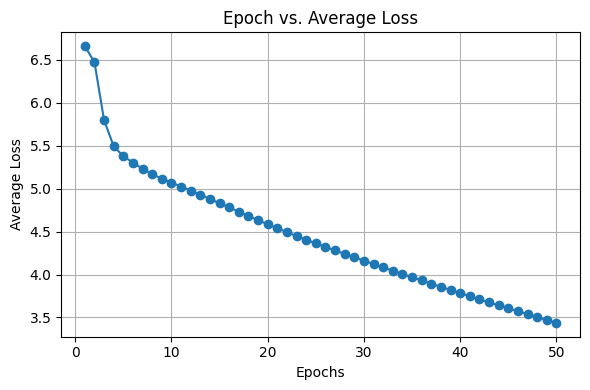

In [5]:
import numpy as np
import matplotlib.pyplot as plt

epoch_num = 50
epoch_losses = [] 

model = CBOW(vocab_size=len(vocab), embed_dim=100, lr=0.02) 

for epoch in range(epoch_num):
    avg_loss = model.train_one_epoch(data)
    ppl = np.exp(avg_loss)
    epoch_losses.append(float(avg_loss))   
    print(f"Epoch {epoch+1}/{epoch_num} | Avg loss: {avg_loss:.4f} | PPL: {ppl:.2f}")

epochs = np.arange(1, epoch_num + 1)

plt.figure(figsize=(6,4))
plt.title('Epoch vs. Average Loss')
plt.plot(epochs, epoch_losses, marker='o')  
plt.xlabel('Epochs')
plt.ylabel('Average Loss')
plt.grid(True)
plt.tight_layout()
plt.show()


## 5. Nearest neighbors (cosine similarity)

We retrieve semantically similar words by nearest neighbors in the embedding space.
Given a word and the `k` parameter, the function `topk_neighbors` will return a list of top k similar words.


In [14]:
import numpy as np

def cosine_similarity(v1, v2):
    # input: 2 vectors
    return (v1 @ v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

def topk_neighbors(word, k, model, word_to_ix, ix_to_word):
    # Please write your code here

    input_idx = word_to_ix[word]
    input_embedding = model.W_in[input_idx]

    similarity = [(cosine_similarity(input_embedding, word), i) for i, word in enumerate(model.W_in) if i != input_idx]
    topK = sorted(similarity, reverse=True)[:k]

    return [(ix_to_word[i], float(s)) for s, i in topK]

k = 10
words = ['daddy', 'mummy', 'want', 'water', 'cat']
for word in words:
    print(topk_neighbors(word, k, model, word_to_ix, ix_to_word))

[('own', 0.6272150874137878), ('let', 0.620528519153595), ('mommy', 0.6119856238365173), ('will', 0.5782183408737183), ('shlom', 0.559371292591095), ('what', 0.5359108448028564), ('much', 0.530728816986084), ('help', 0.5225487351417542), ('cars', 0.5188934803009033), ('maybe', 0.5140525102615356)]
[('nothing', 0.7270411849021912), ('deir', 0.7169003486633301), ('shoes', 0.6907894015312195), ('head', 0.6829562783241272), ('ya', 0.671955406665802), ('glue', 0.6583174467086792), ('purse', 0.6456539630889893), ('middle', 0.6451654434204102), ('himself', 0.6386390328407288), ('dere', 0.6351924538612366)]
[('buy', 0.6289528608322144), ('could', 0.6197921633720398), ('biscuit', 0.6099929809570312), ('paper', 0.5966202020645142), ('kiss', 0.5859124064445496), ('show', 0.5828818082809448), ('eated', 0.5810545086860657), ('take', 0.570949375629425), ('told', 0.566269040107727), ('wants', 0.5661689043045044)]
[('preschool', 0.5560586452484131), ('things', 0.5556604266166687), ('hospital', 0.55182

### Discussion 

Please discuss the results of the similarity calculation with a top_k of 10, using five words: `daddy`, `mummy`, `want`, `water`, `cat` (200 words max).

### Discussion response: 

The words being output suggest that we have captured mostly syntactic similarity rather than semantic similarity. We can see this in the top 10 words that are similar to water - which include hospital, garage, springtime. These are not necessarily related to "water" in the liquid sense, but might instead appear in the context of the word. This may be due to our relatively short window of just 5 words, which we expect to be less capable in capturing the semantic representation of a word. 

However, we might note that there has been some limited success in capturing the semantic meaning of some words. For instance, for the word "daddy", we find that the word "mommy" has the similarity score of 0.611, which is the 3rd highest. This would be consistent with the semantic meaning of the words, given they both represent parents. Interestingly, "daddy" dosen't show up as a top neighbour for the slightly differently spelt "mummy", which might be intepreted as a preserved human or as another spelling for "mommy". Perhaps this might be a reason why "daddy" dosen't show up. 


## 6. Visualise embeddings with SVD (PCA)

We now visualise the high-dimensional word embeddings into a 2D space using Singular Value Decomposition (SVD). 

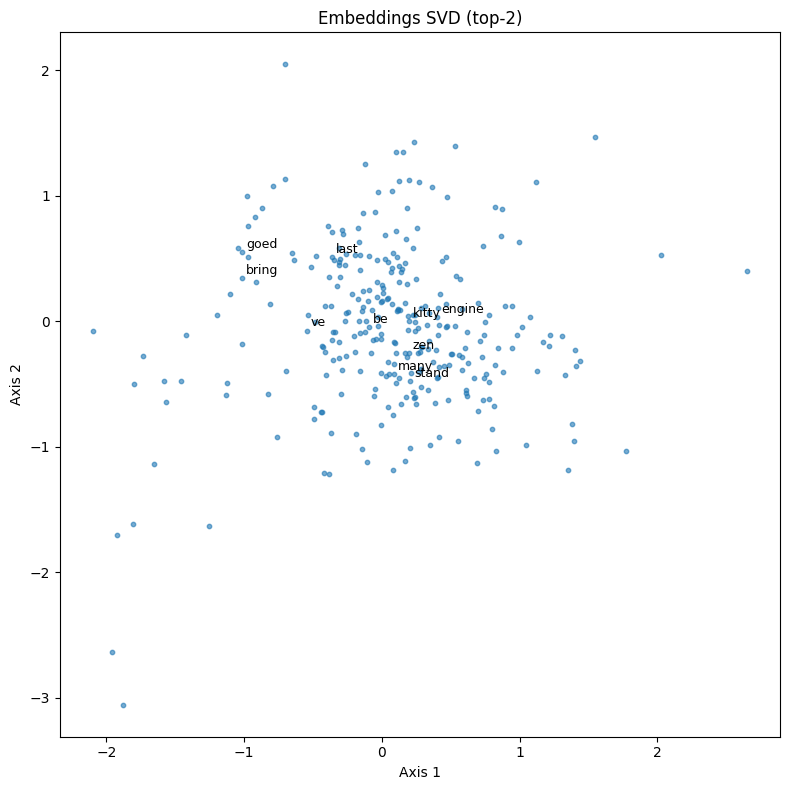

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_embeddings_svd2_simple(
    model,
    ix_to_word,
    max_points=300,
    annotate_k=10,
    random_state=42,
    title="Embeddings SVD (top-2)"
):
    n = min(max_points, model.vocab_size)
    sampled_idx = np.random.default_rng(random_state).choice(model.vocab_size, size=n, replace=False)

    X = model.W_in - model.W_in.mean(axis=0, keepdims=True)

    # note that svd alr gives the descending order, so we can just take the top 2 directions
    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    coords = X[sampled_idx] @ Vt[:2].T 

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.scatter(coords[:, 0], coords[:, 1], s=10, alpha=0.6)

    for j in range(min(annotate_k, n)):
        word = ix_to_word[int(sampled_idx[j])]
        ax.annotate(word, coords[j], fontsize=9, xytext=(3, 3), textcoords="offset points")

    explained_var = (S**2 / np.sum(S**2))[:2]

    ax.set_xlabel(f"Axis 1")
    ax.set_ylabel(f"Axis 2")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

    return coords, explained_var, sampled_idx

coords, explained_var, idx = plot_embeddings_svd2_simple(
    ix_to_word=ix_to_word,
    model=model,              
    max_points=300,
    annotate_k=10,
    random_state=42
)